We simulate the SIR model with low/high endemicity:
$$\begin{align}
    \frac{dS_P}{dt} & = \Lambda - \beta S_P I - \mu S_P \\
    \frac{dI}{dt} & = \beta S_P I + \epsilon\beta S_S I - (\gamma + \mu)I \\
    \frac{dS_S}{dt} & = \gamma I - \epsilon\beta S_S I - \mu S_S.
\end{align}$$
An SDE analogue of this model is
$$\begin{align}
    dS_P & = \big[ \Lambda - \beta S_P I - \mu S_P \big]\, dt + \sqrt{\Lambda}\, dw_1 - \sqrt{\beta S_P I}\, dw_2 - \sqrt{\mu S_P}\, dw_3 \\
    dI & = \big[ \beta S_P I + \epsilon\beta S_S I - (\gamma + \mu)I \big]\, dt + \sqrt{\beta S_P I}\, dw_2 - \sqrt{\mu I}\, dw_4 - \sqrt{\gamma I}\, dw_5 + \sqrt{\epsilon\beta S_S I}\, dw_6 \\
    dS_S & = \big[ \gamma I - \epsilon\beta S_S I - \mu S_S \big]\, dt + \sqrt{\gamma I}\, dw_5 - \sqrt{\epsilon\beta S_S I}\, dw_6 - \sqrt{\mu S_S}\, dw_7
\end{align}$$

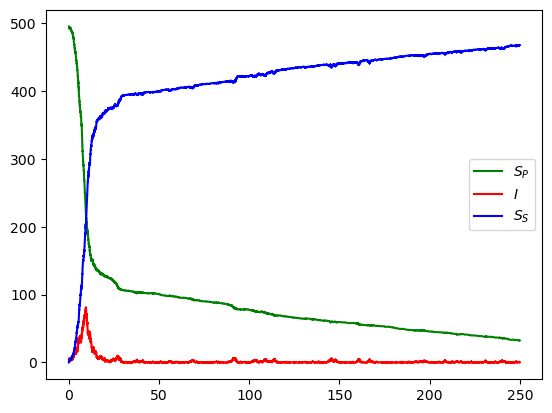

In [189]:
import numpy as np
import matplotlib.pyplot as plt

N = 500
Lambda = 0.0004
mu = 0.0004 / N
beta = 1.5 / N
gamma = 1
epsilon = 0.3

tmax = 250
dt = 0.01
init_cond = [N*0.99, N*0.01, 0]

mu_S_P = lambda X: Lambda - beta*X[0]*X[1] - mu*X[0]
mu_I = lambda X: beta*X[0]*X[1] + epsilon*beta*X[1]*X[2] - (gamma + mu)*X[1]
mu_S_S = lambda X: gamma*X[1] - epsilon*beta*X[1]*X[2] - mu*X[2]

sigma_S_P = lambda X: np.sqrt(np.array([Lambda, beta*X[0]*X[1], mu*X[0]])) * [1, -1, -1]
sigma_I = lambda X: np.sqrt(np.array([beta*X[0]*X[1], mu*X[1], gamma*X[1], epsilon*beta*X[1]*X[2]])) * [1, -1, -1, 1]
sigma_S_S = lambda X: np.sqrt(np.array([gamma*X[1], epsilon*beta*X[1]*X[2], mu*X[2]])) * [1, -1, -1]

restart_S_P_value = 0.1
restart_I_value = 0.1

def Euler_step(X, dt):
    S_P, I, S_S = X
    eta = np.random.normal(0, 1, (7))
    sqrt_dt = np.sqrt(dt)
    S_P_new = S_P + mu_S_P(X)*dt + sigma_S_P(X)*sqrt_dt @ eta[[0,1,2]]
    I_new = I + mu_I(X)*dt + sigma_I(X)*sqrt_dt @ eta[[1,3,4,5]]
    S_S_new = S_S + mu_S_S(X)*dt + sigma_S_S(X)*sqrt_dt @ eta[[4,5,6]]
    if S_S_new <= 0:
        #print('S_S_new <= 0')
        S_P_new = S_P_new + S_S_new
        S_S_new = 0
    if I_new <= 0:
        #print('I_new <= 0')
        S_P_new = S_P_new - (restart_I_value - I_new)
        I_new = restart_I_value
    if S_P_new <= 0:
        #print('S_P_new <= 0')
        S_S_new = S_S_new - (restart_S_P_value - S_P_new)
        S_P_new = restart_S_P_value
    return np.array([S_P_new, I_new, S_S_new])

T = int(np.ceil(tmax / dt))
dt = tmax / T
t_array = np.arange(0, tmax, dt)
sol = np.zeros((T, 3))
sol[0] = init_cond

for n in range(1,T):
    sol[n] = Euler_step(sol[n-1], dt)

plt.plot(t_array, sol[:,0], label=r'$S_P$', color='g')
plt.plot(t_array, sol[:,1], label=r'$I$', color='r')
plt.plot(t_array, sol[:,2], label=r'$S_S$', color='b')
plt.legend()

# Why is the disease dying out immediately (almost) every time?

And when it does persist, why does $I(t)$ blow up?

$\mathcal{R}_\epsilon = 1.50
Number of disease extinctions: 0


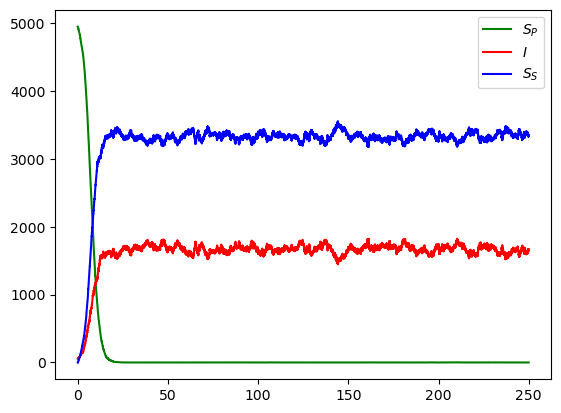

In [26]:
import numpy as np
import matplotlib.pyplot as plt

N = 5000
Lambda = 0.0004
mu = 0.0004 / N
beta = 1.5 / N
gamma = 1
epsilon = 1

R_epsilon = (Lambda / mu) * ((epsilon*beta) / (gamma + mu))

tmax = 250
dt = 0.01
init_cond = [N*0.99, N*0.01, 0]

mu_S_P = lambda X: Lambda - beta*X[0]*X[1] - mu*X[0]
mu_I = lambda X: beta*X[0]*X[1] + epsilon*beta*X[1]*X[2] - (gamma + mu)*X[1]
mu_S_S = lambda X: gamma*X[1] - epsilon*beta*X[1]*X[2] - mu*X[2]

sigma_S_P = lambda X: np.sqrt(np.array([Lambda + mu*X[0], beta*X[0]*X[1]])) * [1, -1]
sigma_I = lambda X: np.sqrt(np.array([beta*X[0]*X[1], mu*X[1], gamma*X[1] + epsilon*beta*X[1]*X[2]])) * [1, 1, 1]
sigma_S_S = lambda X: np.sqrt(np.array([gamma*X[1] + epsilon*beta*X[1]*X[2], mu*X[2]])) * [-1, 1]

restart_S_P_value = 0.1
restart_I_value = 0.1
num_disease_extinctions = 0

def Euler_step(X, dt):
    S_P, I, S_S = X

    extinction_flag = False
    eta = np.random.normal(0, 1, (5))
    sqrt_dt = np.sqrt(dt)

    S_P_new = S_P + mu_S_P(X)*dt + sigma_S_P(X)*sqrt_dt @ eta[[0,1]]
    I_new = I + mu_I(X)*dt + sigma_I(X)*sqrt_dt @ eta[[1,2,3]]
    S_S_new = S_S + mu_S_S(X)*dt + sigma_S_S(X)*sqrt_dt @ eta[[3,4]]

    if S_S_new <= 0:
        #print('S_S_new <= 0')
        S_P_new = S_P_new + S_S_new
        S_S_new = 0
    if I_new <= 0:
        #print('I_new <= 0')
        S_P_new = S_P_new - (restart_I_value - I_new)
        I_new = restart_I_value
        extinction_flag = True
    if S_P_new <= 0:
        #print('S_P_new <= 0')
        S_S_new = S_S_new - (restart_S_P_value - S_P_new)
        S_P_new = restart_S_P_value
    return np.array([S_P_new, I_new, S_S_new]), extinction_flag

T = int(np.ceil(tmax / dt))
dt = tmax / T
t_array = np.arange(0, tmax, dt)
sol = np.zeros((T, 3))
sol[0] = init_cond

for n in range(1,T):
    sol[n], extinction_flag = Euler_step(sol[n-1], dt)
    num_disease_extinctions += 1 if extinction_flag else 0

plt.plot(t_array, sol[:,0], label=r'$S_P$', color='g')
plt.plot(t_array, sol[:,1], label=r'$I$', color='r')
plt.plot(t_array, sol[:,2], label=r'$S_S$', color='b')
plt.legend()

print(r'$\mathcal{R}_\epsilon = ' + f'{R_epsilon:.2f}')
print('Number of disease extinctions: ' + str(num_disease_extinctions))

### How does the number of extinctions change with respect to $\epsilon$?

Completed epsilon = 0.00 (1/10)
Completed epsilon = 0.11 (2/10)
Completed epsilon = 0.22 (3/10)
Completed epsilon = 0.33 (4/10)
Completed epsilon = 0.44 (5/10)
Completed epsilon = 0.56 (6/10)
Completed epsilon = 0.67 (7/10)
Completed epsilon = 0.78 (8/10)
Completed epsilon = 0.89 (9/10)
Completed epsilon = 1.00 (10/10)


C:\Users\daths\AppData\Local\Temp\ipykernel_30960\1356045050.py:102: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


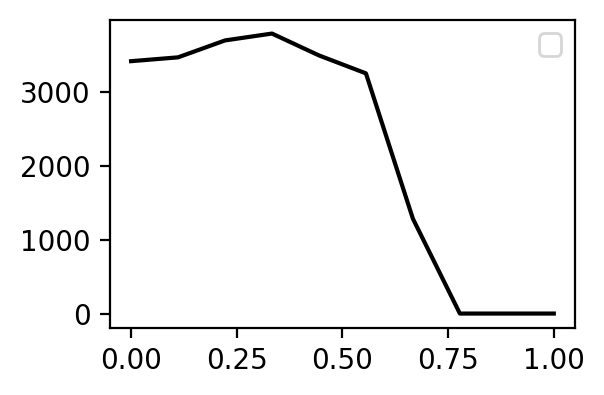

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

'''Class to simulate trajectories of the SIR model'''

class SIR_Simulation:
    def __init__(self, pars):
        self.pars = pars
        self.R_epsilon = (pars['Lambda'] / pars['mu']) * ((pars['epsilon']*pars['beta']) / (pars['gamma'] + pars['mu']))

    def __mu_vector__(self, X):
        N, Lambda, mu, beta, gamma, epsilon = self.pars.values()
        S_P, I, S_S = X
        mu_S_P = Lambda - beta*S_P*I - mu*S_P
        mu_I = beta*S_P*I + epsilon*beta*I*S_S - (gamma + mu)*I
        mu_S_S = gamma*I - epsilon*beta*I*S_S - mu*S_S
        return np.array([mu_S_P, mu_I, mu_S_S])
    
    def __sigma_matrix__(self, X):
        N, Lambda, mu, beta, gamma, epsilon = self.pars.values()
        S_P, I, S_S = X
        G = np.zeros((3, 5))
        
        G[0,0] = np.sqrt(Lambda + mu*S_P)
        G[0,1] = -np.sqrt(beta*S_P*I)
        G[1,1] = G[1,1]
        G[1,2] = np.sqrt(mu*I)
        G[1,3] = np.sqrt(gamma*I + epsilon*beta*S_S*I)
        G[2,3] = -np.sqrt(gamma*I + epsilon*beta*S_S*I)
        G[2,4] = np.sqrt(mu*S_S)

        return G

    def __Euler_step__(self, X, dt):
        restart_S_P_value = 0.1
        restart_I_value = 0.1
        extinction_flag = False
        eta_vector = np.transpose(np.random.normal(0, 1, (5)))

        X_new = X + self.__mu_vector__(X)*dt + self.__sigma_matrix__(X)*np.sqrt(dt)@eta_vector
        S_P_new, I_new, S_S_new = X_new

        if S_S_new <= 0:
            #print('S_S_new <= 0')
            S_P_new = S_P_new + S_S_new
            S_S_new = 0
        if I_new <= 0:
            #print('I_new <= 0')
            S_P_new = S_P_new - (restart_I_value - I_new)
            I_new = restart_I_value
            extinction_flag = True
        if S_P_new <= 0:
            #print('S_P_new <= 0')
            S_S_new = S_S_new - (restart_S_P_value - S_P_new)
            S_P_new = restart_S_P_value
        return np.array([S_P_new, I_new, S_S_new]), extinction_flag

    def simulate_trajectory(self, tmax, dt, init_cond):
        T = int(np.ceil(tmax / dt))
        dt = tmax / T
        t_array = np.arange(0, tmax, dt)
        sol = np.zeros((T, 3))
        sol[0] = init_cond

        num_disease_extinctions = 0

        for n in range(1,T):
            sol[n], extinction_flag = self.__Euler_step__(sol[n-1], dt)
            num_disease_extinctions += 1 if extinction_flag else 0

        return t_array, sol, num_disease_extinctions

pars = {
    'N': 5000,
    'Lambda': 0.0004,
    'mu': 0.0004 / N,
    'beta': 1.5 / N,
    'gamma': 1,
    'epsilon': 0.7,
}

num_epsilon_vals = 10
epsilon_array = np.linspace(0, 1, num_epsilon_vals, endpoint=True)
R_epsilon_array = np.zeros(np.shape(epsilon_array))
disease_extinctions = np.zeros(np.shape(epsilon_array))

tmax = 2000
dt = 0.01
init_cond = [N*0.99, N*0.01, 0]

for i in range(num_epsilon_vals):
    pars['epsilon'] = epsilon_array[i]
    sol = SIR_Simulation(pars)
    R_epsilon_array[i] = sol.R_epsilon
    t_array, sol, num_disease_extinctions = sol.simulate_trajectory(tmax, dt, init_cond)
    disease_extinctions[i] = num_disease_extinctions
    print('Completed epsilon = ' + f'{pars['epsilon']:.2f}' + ' (' + str(i+1) + '/' + str(num_epsilon_vals) + ')')

fig, ax = plt.subplots(1, 1, figsize=(3,2), dpi=200)

ax.plot(epsilon_array, disease_extinctions, color='k')
ax.legend()

Completed beta = 0.0000 (1/100)
Completed beta = 0.0000 (2/100)
Completed beta = 0.0000 (3/100)
Completed beta = 0.0000 (4/100)
Completed beta = 0.0000 (5/100)
Completed beta = 0.0000 (6/100)
Completed beta = 0.0000 (7/100)
Completed beta = 0.0001 (8/100)
Completed beta = 0.0001 (9/100)
Completed beta = 0.0001 (10/100)
Completed beta = 0.0001 (11/100)
Completed beta = 0.0001 (12/100)
Completed beta = 0.0001 (13/100)
Completed beta = 0.0001 (14/100)
Completed beta = 0.0001 (15/100)
Completed beta = 0.0001 (16/100)
Completed beta = 0.0001 (17/100)
Completed beta = 0.0001 (18/100)
Completed beta = 0.0001 (19/100)
Completed beta = 0.0002 (20/100)
Completed beta = 0.0002 (21/100)
Completed beta = 0.0002 (22/100)
Completed beta = 0.0002 (23/100)
Completed beta = 0.0002 (24/100)
Completed beta = 0.0002 (25/100)
Completed beta = 0.0002 (26/100)
Completed beta = 0.0002 (27/100)
Completed beta = 0.0002 (28/100)
Completed beta = 0.0002 (29/100)
Completed beta = 0.0002 (30/100)
Completed beta = 0.

C:\Users\daths\AppData\Local\Temp\ipykernel_30960\373485237.py:104: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


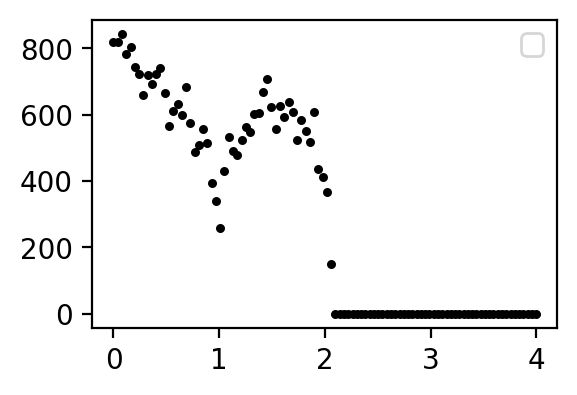

In [70]:
import numpy as np
import matplotlib.pyplot as plt

'''Class to simulate trajectories of the SIR model'''

class SIR_Simulation:
    def __init__(self, pars):
        self.pars = pars
        self.R_epsilon = (pars['Lambda'] / pars['mu']) * ((pars['epsilon']*pars['beta']) / (pars['gamma'] + pars['mu']))

    def __mu_vector__(self, X):
        N, Lambda, mu, beta, gamma, epsilon = self.pars.values()
        S_P, I, S_S = X
        mu_S_P = Lambda - beta*S_P*I - mu*S_P
        mu_I = beta*S_P*I + epsilon*beta*I*S_S - (gamma + mu)*I
        mu_S_S = gamma*I - epsilon*beta*I*S_S - mu*S_S
        return np.array([mu_S_P, mu_I, mu_S_S])
    
    def __sigma_matrix__(self, X):
        N, Lambda, mu, beta, gamma, epsilon = self.pars.values()
        S_P, I, S_S = X
        G = np.zeros((3, 5))
        
        G[0,0] = np.sqrt(Lambda + mu*S_P)
        G[0,1] = -np.sqrt(beta*S_P*I)
        G[1,1] = G[1,1]
        G[1,2] = np.sqrt(mu*I)
        G[1,3] = np.sqrt(gamma*I + epsilon*beta*S_S*I)
        G[2,3] = -np.sqrt(gamma*I + epsilon*beta*S_S*I)
        G[2,4] = np.sqrt(mu*S_S)

        return G

    def __Euler_step__(self, X, dt):
        restart_S_P_value = 0.1
        restart_I_value = 0.1
        extinction_flag = False
        eta_vector = np.transpose(np.random.normal(0, 1, (5)))

        X_new = X + self.__mu_vector__(X)*dt + self.__sigma_matrix__(X)*np.sqrt(dt)@eta_vector
        S_P_new, I_new, S_S_new = X_new

        if S_S_new <= 0:
            #print('S_S_new <= 0')
            S_P_new = S_P_new + S_S_new
            S_S_new = 0
        if I_new <= 0:
            #print('I_new <= 0')
            S_P_new = S_P_new - (restart_I_value - I_new)
            I_new = restart_I_value
            extinction_flag = True
        if S_P_new <= 0:
            #print('S_P_new <= 0')
            S_S_new = S_S_new - (restart_S_P_value - S_P_new)
            S_P_new = restart_S_P_value
        return np.array([S_P_new, I_new, S_S_new]), extinction_flag

    def simulate_trajectory(self, tmax, dt, init_cond):
        T = int(np.ceil(tmax / dt))
        dt = tmax / T
        t_array = np.arange(0, tmax, dt)
        sol = np.zeros((T, 3))
        sol[0] = init_cond

        num_disease_extinctions = 0

        for n in range(1,T):
            sol[n], extinction_flag = self.__Euler_step__(sol[n-1], dt)
            num_disease_extinctions += 1 if extinction_flag else 0

        return t_array, sol, num_disease_extinctions

pars = {
    'N': 5000,
    'Lambda': 0.0004,
    'mu': 0.0004 / N,
    'beta': 1.5 / N,
    'gamma': 1,
    'epsilon': 0.5,
}

num_beta_vals = 100
beta_array = np.linspace(0, 4, num_beta_vals, endpoint=True) / pars['N']
R_epsilon_array = np.zeros(np.shape(beta_array))
disease_extinctions = np.zeros(np.shape(beta_array))

tmax = 400
dt = 0.01
init_cond = [N*0.99, N*0.01, 0]

for i in range(num_beta_vals):
    pars['beta'] = beta_array[i]
    sol = SIR_Simulation(pars)
    R_epsilon_array[i] = sol.R_epsilon
    t_array, sol, num_disease_extinctions = sol.simulate_trajectory(tmax, dt, init_cond)
    disease_extinctions[i] = num_disease_extinctions
    print('Completed beta = ' + f'{pars['beta']:.4f}' + ' (' + str(i+1) + '/' + str(num_beta_vals) + ')')

fig, ax = plt.subplots(1, 1, figsize=(3,2), dpi=200)

R0_array = (pars['Lambda'] / pars['mu']) * (beta_array / (pars['gamma'] + pars['mu']))

ax.scatter(R0_array, disease_extinctions, color='k', s=5)
ax.legend()